## Configuración inicial, importaciones y rutas de archivos

Objetivo: dejar el entorno listo y declarar las rutas de los CSV.

Ajusta las rutas al nombre exacto de tus archivos en el repo.

In [6]:
#Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from pathlib import Path

#Configuración visual de las gráficas
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

#Rutas datasets
RUTA_2022 = Path(
    "../datos/crudos/2022-Tablas-Cruzadas_Octava-Encuesta-de-Percepcion-de-"
    "Calidad-de-Vida_Conjunto-Metropolitano-y-municipios-de-estudio-1"
    "(CONJUNTO METROPOLITANO).csv"
)
RUTA_2024 = Path(
    "../datos/crudos/2024-Tablas-Cruzadas_Novena-Encuesta-de-Percepción-sobre-"
    "Calidad-de-Vida-oct-2024-1(Conjunto).csv"
)

print("Entorno listo")
print(f"2022 → {RUTA_2022.name}  (existe: {RUTA_2022.exists()})")
print(f"2024 → {RUTA_2024.name}  (existe: {RUTA_2024.exists()})")

Entorno listo
2022 → 2022-Tablas-Cruzadas_Octava-Encuesta-de-Percepcion-de-Calidad-de-Vida_Conjunto-Metropolitano-y-municipios-de-estudio-1(CONJUNTO METROPOLITANO).csv  (existe: True)
2024 → 2024-Tablas-Cruzadas_Novena-Encuesta-de-Percepción-sobre-Calidad-de-Vida-oct-2024-1(Conjunto).csv  (existe: True)


## Cargar los CSV crudos y ver su estructura original

Los archivos tienen un formato "ancho" con:
- Fila 1 (idx 0) → agrupadores (Total, Calidad de vida, Municipio, ...)
- Fila 2 (idx 1) → nombres reales de columnas
- Fila 3 (idx 2) → distribución de la muestra (% por categoría)
- Fila 4 en adelante → bloques de preguntas (Q_xx) + filas de respuestas

Leemos SIN encabezado y con separador ";" para inspeccionar todo, probamos varias codificaciones porque el archivo 2024 trae caracteres raros (ż en vez de ¿), típico de un guardado en Latin-1 / cp1252.

In [7]:
def _leer_crudo(ruta: Path) -> pd.DataFrame:
    """Lee un CSV tabular de Jalisco Cómo Vamos sin asignar encabezado."""
    ultimo_error = None
    for enc in ("utf-8", "latin-1", "cp1252"):
        try:
            return pd.read_csv(
                ruta,
                sep=";",
                header=None,
                dtype=str,
                encoding=enc,
                engine="python",
                keep_default_na=False,   # para no convertir "" en NaN sin control
            )
        except UnicodeDecodeError as e:
            ultimo_error = e
            continue
    raise RuntimeError(f"No se pudo leer {ruta} con ninguna codificación. Último error: {ultimo_error}")


df22_raw = _leer_crudo(RUTA_2022)
df24_raw = _leer_crudo(RUTA_2024)

print(f"2022 → shape (filas, columnas) = {df22_raw.shape}")
print(f"2024 → shape (filas, columnas) = {df24_raw.shape}")

print("\nPrimeras 4 filas del archivo 2024 (crudo, sin encabezado)")
display(df24_raw.head(4))

print("\nÚltimas 3 filas del archivo 2024 (crudo)")
display(df24_raw.tail(3))

print("\n¿Cuántas celdas vacías hay por columna en 2024?")
print(df24_raw.isna().sum().to_string())

2022 → shape (filas, columnas) = (2401, 25)
2024 → shape (filas, columnas) = (1985, 24)

Primeras 4 filas del archivo 2024 (crudo, sin encabezado)


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
0,,,Total 2024,Calidad de vida,,,Municipio,,,,...,Edad,,,,Escolaridad,,,N.S.E. (Regla 2024-2022),,
1,Código-2024,,%,1-2,3,4-5,El Salto,Guadalajara,Tlaquepaque,Tlajomulco,...,18-29,30-44,45-59,60+,Sec<,Prep,Univ+,D+/D/E,C/C-,A/B/C+
2,,Pregunta / Respuestas,,"5,5%","38,5%","56,1%","4,3%","29,4%","13,2%","13,2%",...,"29,1%","31,6%","22,9%","16,3%","45,9%","29,9%","24,2%","24,4%","37,4%","38,2%"
3,,,,,,,,,,,...,,,,,,,,,,



Últimas 3 filas del archivo 2024 (crudo)


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
1982,,,,,,,,,,,...,,,,,,,,,,
1983,,,,,,,,,,,...,,,,,,,,,,
1984,,,,,,,,,,,...,,,,,,,,,,



¿Cuántas celdas vacías hay por columna en 2024?
0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0


## Parser: pasar de formato ancho a un DataFrame "tidy" (long)

Estrategia:
1. Asignar los nombres reales de columna (fila 2), respetando que el orden de N.S.E. CAMBIA entre 2022 y 2024.
2. Recorrer fila por fila:
    - Si col 0 tiene un código (empieza con letra) → es PREGUNTA.
    - Si col 0 está vacía y hay pregunta activa → es RESPUESTA.
3. Normalizar números con coma decimal: "12,3%" → 12.3.
4. Devolver una tabla con una fila por (año, pregunta, respuesta, categoría).

In [13]:
#Nombres de columna por posición (24 columnas en ambos años) 
#Nota: N.S.E. cambia de orden entre 2022 y 2024.
COLS_2022 = [
    "codigo", "texto", "total",
    "cv_1_2", "cv_3", "cv_4_5",
    "El Salto", "Guadalajara", "Tlaquepaque", "Tlajomulco", "Tonalá", "Zapopan",
    "Hombre", "Mujer",
    "18-29", "30-44", "45-59", "60+",
    "Sec<", "Prep", "Univ+",
    "A/B/C+", "C/C-", "D+/D/E",   #orden 2022
]

COLS_2024 = [
    "codigo", "texto", "total",
    "cv_1_2", "cv_3", "cv_4_5",
    "El Salto", "Guadalajara", "Tlaquepaque", "Tlajomulco", "Tonalá", "Zapopan",
    "Hombre", "Mujer",
    "18-29", "30-44", "45-59", "60+",
    "Sec<", "Prep", "Univ+",
    "D+/D/E", "C/C-", "A/B/C+",   #orden 2024 (invertido)
]


def _normalizar_numero(valor) -> float:
    """Convierte '12,3%' → 12.3 ; '—' o '' → NaN."""
    if valor is None or pd.isna(valor):
        return np.nan
    s = str(valor).strip().replace("%", "").replace(" ", "")
    if s in ("", "-", "—", "–"):
        return np.nan
    #Quitar separador de miles y cambiar coma decimal
    s = s.replace(".", "").replace(",", ".")
    try:
        return float(s)
    except ValueError:
        return np.nan


def parsear_encuesta(df_raw: pd.DataFrame, cols: list, anio: int) -> pd.DataFrame:
    """Convierte el CSV ancho en una tabla tidy (una fila por respuesta-categoría)."""
    df = df_raw.copy()

    #Garantizar exactamente 24 columnas
    while df.shape[1] < 24:
        df[df.shape[1]] = ""
    df = df.iloc[:, :24]
    df.columns = cols

    filas = []
    codigo_actual, texto_actual = None, None

    for _, row in df.iterrows():
        cod = "" if pd.isna(row["codigo"]) else str(row["codigo"]).strip()
        txt = "" if pd.isna(row["texto"]) else str(row["texto"]).strip()

        #Caso 1: fila de PREGUNTA (código no vacío que empieza con letra) 
        if cod and cod[0].isalpha():
            codigo_actual = cod
            texto_actual = txt
            continue

        #Caso 2: fila de RESPUESTA (col 0 vacía, col 1 con texto) 
        if codigo_actual and txt:
            #Ignorar la fila de metadatos de muestra
            if txt.lower().startswith("pregunta / respuestas"):
                continue
            registro = {
                "anio": anio,
                "codigo": codigo_actual,
                "pregunta": texto_actual,
                "respuesta": txt,
            }
            for c in cols[2:]:
                registro[c] = _normalizar_numero(row[c])
            filas.append(registro)

    return pd.DataFrame(filas)


#Ejecutar el parser sobre ambos años 
tidy_2022 = parsear_encuesta(df22_raw, COLS_2022, 2022)
tidy_2024 = parsear_encuesta(df24_raw, COLS_2024, 2024)

print(f"tidy_2022 → shape = {tidy_2022.shape}")
print(f"tidy_2024 → shape = {tidy_2024.shape}")

print("\n2022")
print("Vista rápida: tidy_2022.head(10) ")
display(tidy_2022.head(10))

print("\nPreguntas únicas detectadas en 2022 ")
print(f"Total: {tidy_2022['codigo'].nunique()} códigos de pregunta distintos\n")
conteo = tidy_2022.groupby("codigo").size().sort_index()
print(conteo.to_string())

print("\n2024")
print("Vista rápida: tidy_2024.head(10) ")
display(tidy_2024.head(10))

print("\nPreguntas únicas detectadas en 2024 ")
print(f"Total: {tidy_2024['codigo'].nunique()} códigos de pregunta distintos\n")
conteo = tidy_2024.groupby("codigo").size().sort_index()
print(conteo.to_string())

tidy_2022 → shape = (1896, 26)
tidy_2024 → shape = (1546, 26)

2022
Vista rápida: tidy_2022.head(10) 


,anio,codigo,pregunta,respuesta,total,cv_1_2,cv_3,cv_4_5,El Salto,Guadalajara,...,18-29,30-44,45-59,60+,Sec<,Prep,Univ+,A/B/C+,C/C-,D+/D/E
0,2022,Q_1,"En una escala del 1 al 5, donde... significa.....",No sabe/No contestó,0.1,0.5,0.1,0.1,0.5,NaN,...,0.1,0.3,0.1,NaN,0.2,0.3,NaN,0.1,0.1,0.2
1,2022,Q_1,"En una escala del 1 al 5, donde... significa.....",Nada satisfecha(o),1.6,10.5,1.7,0.5,1.0,0.5,...,1.7,1.2,1.0,3.2,2.4,0.8,1.0,0.6,1.7,2.8
2,2022,Q_1,"En una escala del 1 al 5, donde... significa.....",Poco satisfecha(o),4.7,27.7,5.2,1.8,4.1,5.5,...,2.5,4.4,5.1,8.8,6.4,3.3,3.2,3.4,3.9,7.5
3,2022,Q_1,"En una escala del 1 al 5, donde... significa.....","Ni satisfecha(o), ni insatisfecha(o)",7.3,11.8,13.7,3.3,6.6,8.4,...,7.5,5.5,7.9,8.5,7.9,7.5,5.9,5.9,8.0,7.7
4,2022,Q_1,"En una escala del 1 al 5, donde... significa.....",Algo satisfecha(o),23.1,21.3,26.4,21.6,25.2,25.2,...,27.0,23.6,21.2,18.8,22.3,24.1,23.8,20.4,26.5,21.8
5,2022,Q_1,"En una escala del 1 al 5, donde... significa.....",Muy satisfecha(o),63.1,28.2,53.0,72.7,62.6,60.3,...,61.2,65.0,64.7,60.7,60.9,64.1,66.1,69.7,59.8,59.9
6,2022,Q_1,"En una escala del 1 al 5, donde... significa.....",Promedio,4.4,3.3,4.2,4.6,4.5,4.4,...,4.4,4.5,4.4,4.3,4.3,4.5,4.5,4.6,4.4,4.3
7,2022,Q_3,"En una escala del 1 al 5, donde... significa.....",Nada feliz,1.0,8.0,0.9,0.2,0.5,0.7,...,0.1,1.3,1.0,1.9,1.7,0.1,0.4,0.2,1.1,1.7
8,2022,Q_3,"En una escala del 1 al 5, donde... significa.....",Poco feliz,4.8,25.8,5.5,1.8,5.4,4.5,...,5.3,3.9,3.1,8.2,6.6,3.6,2.7,3.3,3.4,8.3
9,2022,Q_3,"En una escala del 1 al 5, donde... significa.....","Ni feliz, ni infeliz",9.7,15.2,17.3,5.0,8.1,10.0,...,8.8,7.5,11.4,12.1,11.9,7.7,7.8,7.8,9.7,12.2



Preguntas únicas detectadas en 2022 
Total: 247 códigos de pregunta distintos

codigo
Q_1                 7
Q_10                7
Q_11                8
Q_14               11
Q_14_S             20
Q_15_S_T_Q_15_1    22
Q_15_S_T_Q_15_2    26
Q_15_S_T_Q_15_3    22
Q_15_S_T_Q_15_4    27
Q_15_S_T_Q_15_5    19
Q_15_S_T_Q_15_6    18
Q_16                7
Q_17                4
Q_19               48
Q_20                5
Q_21                3
Q_22                4
Q_23                3
Q_25                7
Q_26_O1             8
Q_26_O2             9
Q_26_O3             9
Q_27                7
Q_27_S              7
Q_3                 7
Q_34_O1             8
Q_34_O2             9
Q_34_O3             9
Q_34_O4             9
Q_34_O5             9
Q_34_O6             9
Q_35                3
Q_36                7
Q_37                7
Q_39                7
Q_4                 5
Q_43               11
Q_43_S              6
Q_45               52
Q_48               52
Q_4_S              15
Q_5        

,anio,codigo,pregunta,respuesta,total,cv_1_2,cv_3,cv_4_5,El Salto,Guadalajara,...,18-29,30-44,45-59,60+,Sec<,Prep,Univ+,D+/D/E,C/C-,A/B/C+
0,2024,Q_1,"En una escala del 1 al 5, donde 1 significa ""N...",Nada satisfecha(o),1.5,15.6,1.4,0.2,1.3,1.4,...,0.9,0.7,1.8,3.5,2.3,1.2,0.3,2.6,1.0,1.1
1,2024,Q_1,"En una escala del 1 al 5, donde 1 significa ""N...",Poco satisfecha(o),3.0,16.5,4.5,0.7,4.6,2.7,...,1.6,3.0,3.1,5.2,4.1,2.6,1.3,5.5,2.6,1.8
2,2024,Q_1,"En una escala del 1 al 5, donde 1 significa ""N...","Ni satisfecha(o), ni insatisfecha(o)",8.1,16.5,13.7,3.4,9.3,6.3,...,6.7,8.4,7.3,11.0,9.9,7.6,5.3,9.5,8.9,6.6
3,2024,Q_1,"En una escala del 1 al 5, donde 1 significa ""N...",Algo satisfecha(o),28.5,27.3,34.6,24.5,27.9,31.1,...,34.2,27.5,28.8,20.1,26.6,29.8,30.7,25.6,28.3,30.9
4,2024,Q_1,"En una escala del 1 al 5, donde 1 significa ""N...",Muy satisfecha(o),58.8,24.1,45.8,71.1,56.9,58.2,...,56.6,60.1,58.9,60.2,56.8,58.8,62.4,56.4,59.2,59.6
5,2024,Q_1,"En una escala del 1 al 5, donde 1 significa ""N...",No sabe/No contestó (NO LEER),0.1,NaN,NaN,0.2,NaN,0.3,...,NaN,0.3,NaN,NaN,0.2,NaN,NaN,0.5,NaN,NaN
6,2024,Q_1,"En una escala del 1 al 5, donde 1 significa ""N...",Promedio,4.4,3.3,4.2,4.7,4.3,4.4,...,4.4,4.4,4.4,4.3,4.3,4.4,4.5,4.3,4.4,4.5
7,2024,Q_2,"En una escala del 1 al 5, donde 1 significa ""M...",Muy baja,1.8,32.9,NaN,NaN,2.4,1.6,...,0.6,1.9,1.8,3.8,2.5,2.0,0.3,4.0,1.6,0.7
8,2024,Q_2,"En una escala del 1 al 5, donde 1 significa ""M...",Algo baja,3.7,67.1,NaN,NaN,5.3,5.3,...,1.2,3.2,5.2,7.0,4.9,2.9,2.2,6.1,3.5,2.5
9,2024,Q_2,"En una escala del 1 al 5, donde 1 significa ""M...","Ni baja, ni alta",38.4,NaN,100.0,NaN,42.6,37.9,...,36.8,37.5,39.9,40.9,45.0,38.8,25.5,46.7,40.3,31.6



Preguntas únicas detectadas en 2024 
Total: 209 códigos de pregunta distintos

codigo
Q_1           7
Q_10          7
Q_11          8
Q_14          7
Q_15          4
Q_16         35
Q_17          5
Q_18          3
Q_19          4
Q_2           7
Q_20          3
Q_21          3
Q_22          7
Q_23_O1       9
Q_23_O2      10
Q_23_O3      10
Q_23_O4      10
Q_23_O5      10
Q_24          8
Q_3           7
Q_31          3
Q_32          7
Q_33          7
Q_34_O1      14
Q_34_O10     15
Q_34_O11     15
Q_34_O12     15
Q_34_O13     15
Q_34_O2      15
Q_34_O3      15
Q_34_O4      15
Q_34_O5      15
Q_34_O6      15
Q_34_O7      15
Q_34_O8      15
Q_34_O9      15
Q_35          7
Q_38         11
Q_4           5
Q_40         59
Q_40_C       10
Q_41          4
Q_42         36
Q_42_C        7
Q_44          7
Q_45          4
Q_46_O1       7
Q_46_O2       7
Q_46_O3       7
Q_46_O4       7
Q_46_O5       7
Q_47         15
Q_48          8
Q_49          7
Q_5           7
Q_50          7
Q_51          4
Q

## Verificación de cobertura y distribución de la muestra

Objetivo: confirmar que
- Los municipios del AMG están completos,
- Los porcentajes de la fila 3 (muestra) se conservaron bien,
- No hay nulos raros por columna.

In [16]:
print("DISTRIBUCIÓN DE LA MUESTRA POR MUNICIPIO (fila 3 del CSV)")

#Reconstruimos la fila de muestra desde el CSV crudo (índice 2)
muestra_2024 = df24_raw.iloc[2, 6:12].tolist()   #cols 6-11 = municipios
muestra_2022 = df22_raw.iloc[2, 6:12].tolist()
municipios = COLS_2024[6:12]

tabla_muestra = pd.DataFrame({
    "municipio": municipios,
    "%_2022": [_normalizar_numero(x) for x in muestra_2022],
    "%_2024": [_normalizar_numero(x) for x in muestra_2024],
}).round(2)

display(tabla_muestra)

print("\n")
print("NULOS POR COLUMNA EN tidy_2024 (top 10 con más vacíos)")
nulos = tidy_2024.drop(columns=["anio", "codigo", "pregunta", "respuesta"]).isna().sum().sort_values(ascending=False)
print(nulos.head(10).to_string())

print("\n")
print("NULOS POR COLUMNA EN tidy_2022 (top 10 con más vacíos)")
nulos22 = tidy_2022.drop(columns=["anio", "codigo", "pregunta", "respuesta"]).isna().sum().sort_values(ascending=False)
print(nulos22.head(10).to_string())

print("\n")
print("CHEQUEO RÁPIDO: ¿Los % de 'total' suman ~100 por pregunta?")
print("(Solo preguntas de escala Likert / categóricas simples — muestra)")

#Tomamos algunas preguntas "clásicas" de escala para verificar sumas
muestra_codigos = ["Q_1", "Q_3", "Q_49", "Q_50", "Q_51", "Q_53", "T_Q_72_8"]
for cod in muestra_codigos:
    sub = tidy_2024[tidy_2024["codigo"] == cod]
    if len(sub) == 0:
        continue
    total_sum = sub["total"].sum()
    print(f"  {cod:10s} → {len(sub):2d} respuestas | suma % total = {total_sum:6.1f}%")

DISTRIBUCIÓN DE LA MUESTRA POR MUNICIPIO (fila 3 del CSV)


,municipio,%_2022,%_2024
0,El Salto,4.3,4.3
1,Guadalajara,29.4,29.4
2,Tlaquepaque,13.2,13.2
3,Tlajomulco,13.2,13.2
4,Tonalá,10.7,10.7
5,Zapopan,29.3,29.2




NULOS POR COLUMNA EN tidy_2024 (top 10 con más vacíos)
cv_1_2         448
Tlaquepaque    384
60+            345
Tlajomulco     342
El Salto       339
Guadalajara    338
Zapopan        327
Univ+          322
Tonalá         321
18-29          306


NULOS POR COLUMNA EN tidy_2022 (top 10 con más vacíos)
cv_1_2         504
Tlajomulco     493
Guadalajara    461
60+            456
El Salto       448
Tlaquepaque    447
Zapopan        440
Tonalá         432
Univ+          407
Prep           389


CHEQUEO RÁPIDO: ¿Los % de 'total' suman ~100 por pregunta?
(Solo preguntas de escala Likert / categóricas simples — muestra)
  Q_1        →  7 respuestas | suma % total =  104.4%
  Q_3        →  7 respuestas | suma % total =  104.3%
  Q_49       →  7 respuestas | suma % total =  102.8%
  Q_50       →  7 respuestas | suma % total =  103.0%
  Q_51       →  4 respuestas | suma % total =  100.0%
  Q_53       →  4 respuestas | suma % total =  100.0%
  T_Q_72_8   →  8 respuestas | suma % total =  102.1%


## Limpiar el tidy: quitar "Promedio" y "No sabe / No contestó"

Problema: en la celda anterior las sumas de "total" daban >100% porque se estaba contando la fila "Promedio" (que es un valor 1-5, NO un %) y
la fila "No sabe / No contestó" (que no es categoría de respuesta).

Solución: crear versiones "limpias" sin esas filas, conservando las versiones originales para cuando queramos reportar NS/NC.

In [ ]:
def limpiar_tidy(df: pd.DataFrame) -> pd.DataFrame:
    """Quita filas de 'Promedio' y 'No sabe/No contestó'. Conserva 'No aplica'."""
    resp = df["respuesta"].astype(str).str.strip().str.lower()
    es_promedio = resp.str.startswith("promedio")
    es_nsnc = (
        resp.str.startswith("no sabe")
        | resp.str.startswith("no contestó")
        | resp.str.startswith("no sabría")
    )
    return df[~(es_promedio | es_nsnc)].copy()


tidy_2022_limpio = limpiar_tidy(tidy_2022)
tidy_2024_limpio = limpiar_tidy(tidy_2024)

print(f"tidy_2022_limpio → {tidy_2022_limpio.shape}  (antes: {tidy_2022.shape})")
print(f"tidy_2024_limpio → {tidy_2024_limpio.shape}  (antes: {tidy_2024.shape})")

#Re-verificación deben sumar ~100%
print("\nVerificación: ¿ya suman ~100%?")
for cod in ["Q_1", "Q_3", "Q_49", "Q_50", "Q_51", "Q_53", "T_Q_72_8"]:
    sub = tidy_2024_limpio[tidy_2024_limpio["codigo"] == cod]
    if len(sub) == 0:
        continue
    print(f"  {cod:12s} → {len(sub):2d} resp | suma % total = {sub['total'].sum():6.1f}%")

tidy_2022_limpio → (1572, 26)  (antes: (1896, 26))
tidy_2024_limpio → (1231, 26)  (antes: (1546, 26))

Verificación: ¿ya suman ~100%?
  Q_1          →  5 resp | suma % total =   99.9%
  Q_3          →  5 resp | suma % total =  100.0%
  Q_49         →  5 resp | suma % total =   99.7%
  Q_50         →  5 resp | suma % total =   99.7%
  Q_51         →  3 resp | suma % total =   99.8%
  Q_53         →  3 resp | suma % total =  100.0%
  T_Q_72_8     →  5 resp | suma % total =   99.2%


## Mapa de equivalencia de códigos entre 2022 y 2024

IMPORTANTE: la numeración cambió entre años. Sin este mapa, comparar "Q_50 de 2022" con "Q_50 de 2024" daría resultados falsos.\
El mapa se construyó revisando el texto literal de cada pregunta.

In [19]:
MAPA = {
    #Variables centrales del proyecto (Percepción vs Cifra Negra)
    "percepcion_ciudad":  {"2022": "Q_50",     "2024": "Q_49"},
    "percepcion_colonia": {"2022": "Q_51",     "2024": "Q_50"},
    "victima_delito":     {"2022": "Q_52",     "2024": "Q_51"},
    "tipo_delito":        {"2022": "Q_53",     "2024": "Q_52"},
    "denuncio":           {"2022": "Q_54",     "2024": "Q_53"},
    "razon_no_denuncio":  {"2022": "Q_56",     "2024": "Q_55"},
    "confianza_policia":  {"2022": "T_Q_74_7", "2024": "T_Q_72_8"},
    "confianza_ejercito": {"2022": "T_Q_74_8", "2024": "T_Q_72_9"},
    "confianza_gobierno": {"2022": "T_Q_74_5", "2024": "T_Q_72_6"},
    "confianza_fiscalia": {"2022": "T_Q_74_10","2024": "T_Q_72_11"},
    "confianza_udeg":     {"2022": "T_Q_74_11","2024": "T_Q_72_12"},
}

#Validación: verificar que cada código existe en el tidy de su año
print(f"{'Variable':<22} {'Año':<5} {'Código':<11} {'OK?':<4} Texto de la pregunta")
print("-" * 115)

for var, anios in MAPA.items():
    for anio, cod in anios.items():
        df = tidy_2022_limpio if anio == "2022" else tidy_2024_limpio
        match = df[df["codigo"] == cod]
        existe = "✓" if len(match) > 0 else "✗"
        texto = (match["pregunta"].iloc[0][:55] + "...") if len(match) > 0 else "—"
        print(f"{var:<22} {anio:<5} {cod:<11} {existe:<4} {texto}")

Variable               Año   Código      OK?  Texto de la pregunta
-------------------------------------------------------------------------------------------------------------------
percepcion_ciudad      2022  Q_50        ✓    Ahora le voy a preguntar algunos aspectos de la segurid...
percepcion_ciudad      2024  Q_49        ✓    Ahora le voy a preguntar algunos aspectos de la segurid...
percepcion_colonia     2022  Q_51        ✓    ¿Considera usted que vivir en esta COLONIA es nada segu...
percepcion_colonia     2024  Q_50        ✓    ¿Considera usted que vivir en esta COLONIA es nada segu...
victima_delito         2022  Q_52        ✓    ¿Fue usted víctima de algún delito en los últimos doce ...
victima_delito         2024  Q_51        ✓    ¿Fue usted víctima de algún delito en los últimos doce ...
tipo_delito            2022  Q_53        ✓    ¿De qué tipo de delito fue víctima? (Si fue víctima de ...
tipo_delito            2024  Q_52        ✓    ¿De qué tipo de delito fue víctima? 

## Percepción de inseguridad por municipio (2022 vs 2024)

Métrica: % que se siente insegur@ en su CIUDAD = "Nada seguro" + "Poco seguro"

Produce: tabla comparativa + gráfico de barras agrupadas

PERCEPCIÓN DE INSEGURIDAD EN LA CIUDAD (% que se siente inseguro)


,2022,2024,Δ 2022→2024 (pp)
Municipio / Región,,,
El Salto,58.7,51.3,-7.4
Tlaquepaque,55.6,51.3,-4.3
Guadalajara,60.2,45.3,-14.9
Tlajomulco,63.5,45.1,-18.4
Total AMG,57.2,45.0,-12.2
Tonalá,52.2,45.0,-7.2
Zapopan,53.7,40.8,-12.9


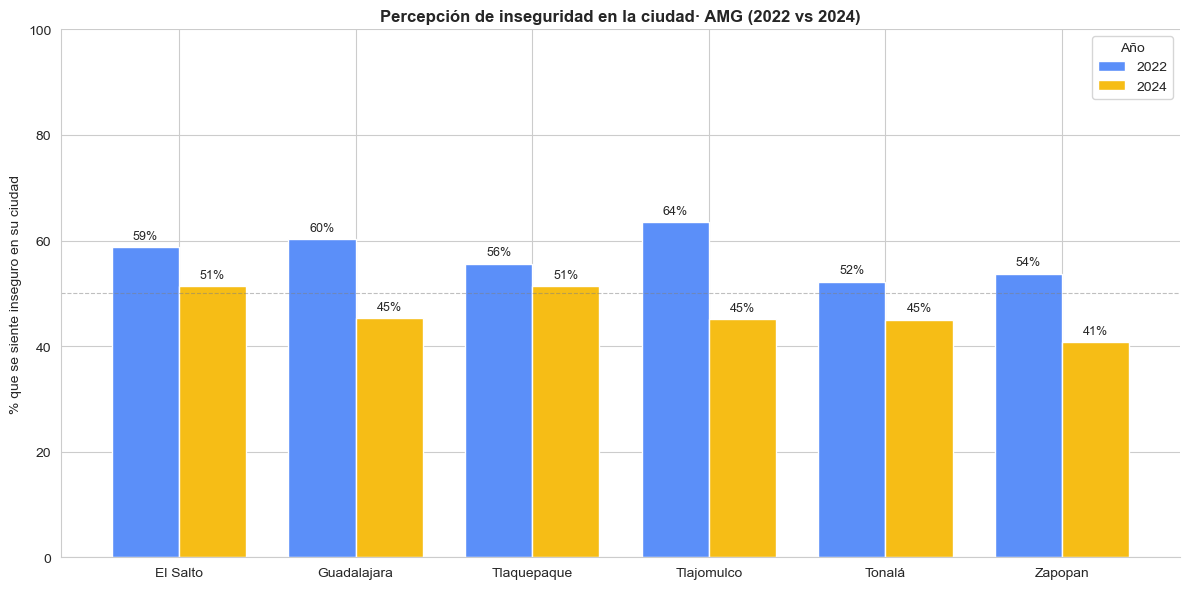

In [20]:
MUNICIPIOS = ["El Salto", "Guadalajara", "Tlaquepaque",
              "Tlajomulco", "Tonalá", "Zapopan"]


def pct_inseguridad(df: pd.DataFrame, codigo: str) -> dict:
    """% que se siente insegur@ = 'Nada seguro' + 'Poco seguro'."""
    sub = df[df["codigo"] == codigo].copy()
    if sub.empty:
        return {}
    resp = sub["respuesta"].astype(str).str.lower()
    es_inseguro = resp.str.contains("nada seguro|poco seguro", regex=True)

    fila = {"Total AMG": sub.loc[es_inseguro, "total"].sum()}
    for m in MUNICIPIOS:
        if m in sub.columns:
            fila[m] = sub.loc[es_inseguro, m].sum()
    return fila


data_perc = {
    2022: pct_inseguridad(tidy_2022_limpio, MAPA["percepcion_ciudad"]["2022"]),
    2024: pct_inseguridad(tidy_2024_limpio, MAPA["percepcion_ciudad"]["2024"]),
}

tabla_perc = pd.DataFrame(data_perc).round(1)
tabla_perc.index.name = "Municipio / Región"
tabla_perc["Δ 2022→2024 (pp)"] = (tabla_perc[2024] - tabla_perc[2022]).round(1)

print("PERCEPCIÓN DE INSEGURIDAD EN LA CIUDAD (% que se siente inseguro)")
display(tabla_perc.sort_values(2024, ascending=False))

#Visualización
fig, ax = plt.subplots(figsize=(12, 6))

plot = tabla_perc.drop(index="Total AMG", errors="ignore")
x = np.arange(len(plot))
ancho = 0.38

b22 = ax.bar(x - ancho/2, plot[2022], ancho,
             label="2022", color="#5B8FF9", edgecolor="white")
b24 = ax.bar(x + ancho/2, plot[2024], ancho,
             label="2024", color="#F6BD16", edgecolor="white")

for b in list(b22) + list(b24):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1,
            f"{b.get_height():.0f}%", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(plot.index)
ax.set_ylabel("% que se siente inseguro en su ciudad")
ax.set_title("Percepción de inseguridad en la ciudad· AMG (2022 vs 2024)")
ax.set_ylim(0, 100)
ax.axhline(50, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
ax.legend(title="Año")
sns.despine()
plt.tight_layout()
plt.show()

## Cifra negra local: víctimas que NO denunciaron (2022 vs 2024)

Definición (cercana a ENVIPE) = % de víctimas que NO denunciaron.

Flujo:
1. ¿Fue víctima?  → "Sí, de un delito" + "Sí, de más de un delito"
2. ¿Denunció?     → "Sí" vs "No" (excluye "No aplica", que son no-víctimas)
3. Cifra negra    = "No" / ("Sí" + "No") × 100

In [ ]:
def cifra_negra(df: pd.DataFrame, cod_victima: str, cod_denuncio: str, categoria: str = "total") -> dict:
    """Cifra negra = % de víctimas que NO denunciaron."""
    v = df[df["codigo"] == cod_victima]
    d = df[df["codigo"] == cod_denuncio]
    if v.empty or d.empty:
        return {"error": "sin datos"}

    resp_v = v["respuesta"].astype(str).str.strip().str.lower()
    pct_victimas = v.loc[resp_v.str.startswith("sí"), categoria].sum()

    resp_d = d["respuesta"].astype(str).str.strip().str.lower()
    pct_si = d.loc[resp_d == "sí", categoria].sum()
    pct_no = d.loc[resp_d == "no", categoria].sum()

    base = pct_si + pct_no
    cifra = (pct_no / base * 100) if base > 0 else np.nan

    return {
        "anio": int(df["anio"].iloc[0]),
        "% víctimas":                   round(pct_victimas, 1),
        "% víctimas que denunciaron":   round(pct_si, 1),
        "% víctimas que NO denunciaron": round(pct_no, 1),
        "cifra negra (% víctimas)":     round(cifra, 1) if pd.notna(cifra) else None,
    }


#Tabla comparativa por categoría territorial
def cifra_negra_tabla(df_22, df_24):
    filas = []
    for cat in ["total"] + MUNICIPIOS:
        r22 = cifra_negra(df_22, MAPA["victima_delito"]["2022"],
                          MAPA["denuncio"]["2022"], categoria=cat)
        r24 = cifra_negra(df_24, MAPA["victima_delito"]["2024"],
                          MAPA["denuncio"]["2024"], categoria=cat)
        delta = (
            round(r24.get("cifra negra (% víctimas)", np.nan)
                  - r22.get("cifra negra (% víctimas)", np.nan), 1)
            if None not in (r22.get("cifra negra (% víctimas)"),
                            r24.get("cifra negra (% víctimas)"))
            else None
        )
        filas.append({
            "Categoría": "Total AMG" if cat == "total" else cat,
            "Cifra negra 2022 (%)": r22.get("cifra negra (% víctimas)"),
            "Cifra negra 2024 (%)": r24.get("cifra negra (% víctimas)"),
            "Δ (pp)": delta,
        })
    return pd.DataFrame(filas)


tabla_cifra = cifra_negra_tabla(tidy_2022_limpio, tidy_2024_limpio)
print("CIFRA NEGRA LOCAL — % de víctimas que NO denunciaron")
display(tabla_cifra)

CIFRA NEGRA LOCAL — % de víctimas que NO denunciaron


,Categoría,Cifra negra 2022 (%),Cifra negra 2024 (%),Δ (pp)
0,Total AMG,65.1,59.2,-5.9
1,El Salto,66.7,62.0,-4.7
2,Guadalajara,60.6,46.5,-14.1
3,Tlaquepaque,64.8,58.5,-6.3
4,Tlajomulco,59.1,64.8,5.7
5,Tonalá,68.7,70.4,1.7
6,Zapopan,73.8,68.7,-5.1


## Confianza en la policía (escala 1-5)

Distribución completa de respuestas (Nada → Mucha) por año, comparando Zapopan vs Total AMG.

CONFIANZA EN LA POLICÍA — 2022 (%)


,Total AMG,Zapopan
respuesta,,
Nada,54.4,57.5
Poco,20.5,20.6
Ni confío ni desconfío,11.1,10.2
Algo,10.0,8.0
Mucha,3.1,2.9



CONFIANZA EN LA POLICÍA — 2024 (%)


,Total AMG,Zapopan
respuesta,,
Nada,42.5,34.1
Poco,23.9,26.4
Ni confío ni desconfío,17.7,19.9
Algo,11.0,13.4
Mucha,4.1,4.6


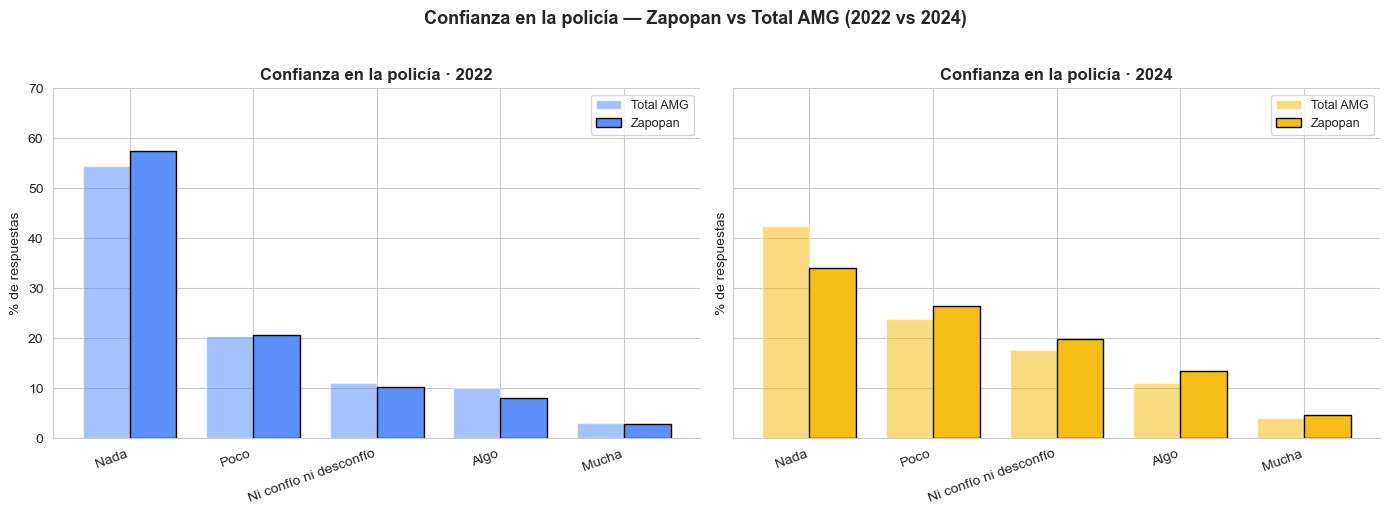


INSIGHT: % que dijo 'Nada' de confianza en la policía
  2022 → Total AMG: 54.4% | Zapopan: 57.5%
  2024 → Total AMG: 42.5% | Zapopan: 34.1%


In [23]:
ESCALA_CONF = ["Nada", "Poco", "Ni confío ni desconfío", "Algo", "Mucha"]

def dist_confianza(df: pd.DataFrame, codigo: str) -> pd.DataFrame:
    sub = df[df["codigo"] == codigo].copy()
    if sub.empty:
        return pd.DataFrame()
    resp = sub["respuesta"].astype(str).str.strip()
    sub = sub[resp.isin(ESCALA_CONF)].copy()
    sub["respuesta"] = pd.Categorical(sub["respuesta"], categories=ESCALA_CONF, ordered=True)
    sub = sub.sort_values("respuesta")
    return sub[["respuesta", "total", "Zapopan"]].rename(
        columns={"total": "Total AMG", "Zapopan": "Zapopan"}
    ).set_index("respuesta")


d22 = dist_confianza(tidy_2022_limpio, MAPA["confianza_policia"]["2022"])
d24 = dist_confianza(tidy_2024_limpio, MAPA["confianza_policia"]["2024"])

print("CONFIANZA EN LA POLICÍA — 2022 (%)")
display(d22.round(1))
print("\nCONFIANZA EN LA POLICÍA — 2024 (%)")
display(d24.round(1))

#Gráfico comparativo
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (anio, d, color) in zip(
    axes,
    [(2022, d22, "#5B8FF9"), (2024, d24, "#F6BD16")],
):
    idx = np.arange(len(d))
    ancho = 0.38
    ax.bar(idx - ancho/2, d["Total AMG"], ancho,
           label="Total AMG", color=color, alpha=0.55, edgecolor="white")
    ax.bar(idx + ancho/2, d["Zapopan"], ancho,
           label="Zapopan", color=color, edgecolor="black")
    ax.set_xticks(idx)
    ax.set_xticklabels(d.index, rotation=20, ha="right")
    ax.set_title(f"Confianza en la policía · {anio}")
    ax.set_ylabel("% de respuestas")
    ax.set_ylim(0, 70)
    ax.legend(fontsize=9)
    sns.despine(ax=ax)

plt.suptitle("Confianza en la policía — Zapopan vs Total AMG (2022 vs 2024)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

#Insight rápido
print("\nINSIGHT: % que dijo 'Nada' de confianza en la policía")
for nombre, d in [("2022", d22), ("2024", d24)]:
    if "Nada" in d.index:
        print(f"  {nombre} → Total AMG: {d.loc['Nada', 'Total AMG']:.1f}% | "
              f"Zapopan: {d.loc['Nada', 'Zapopan']:.1f}%")

## Heatmap comparativo: percepción × cifra negra × confianza

Tres métricas clave del proyecto en un solo panel:
- Percepción inseguridad (%)      → más alto = peor
- Cifra negra (%)                 → más alto = peor
- Confianza en policía (% "Nada") → más alto = peor

Colormap divergente (RdYlGn_r): verde = bajo/bueno, rojo = alto/malo.

TABLA COMPARATIVA — 3 MÉTRICAS CLAVE POR MUNICIPIO


,Percepción 2022,Percepción 2024,Cifra Negra 2022,Cifra Negra 2024,Conf. Nada 2022,Conf. Nada 2024
Total AMG,57.2,45.0,65.1,59.2,54.4,42.5
El Salto,58.7,51.3,66.7,62.0,53.4,53.5
Guadalajara,60.2,45.3,60.6,46.5,52.9,43.9
Tlaquepaque,55.6,51.3,64.8,58.5,47.9,44.0
Tlajomulco,63.5,45.1,59.1,64.8,61.5,51.7
Tonalá,52.2,45.0,68.7,70.4,49.4,44.3
Zapopan,53.7,40.8,73.8,68.7,57.5,34.1


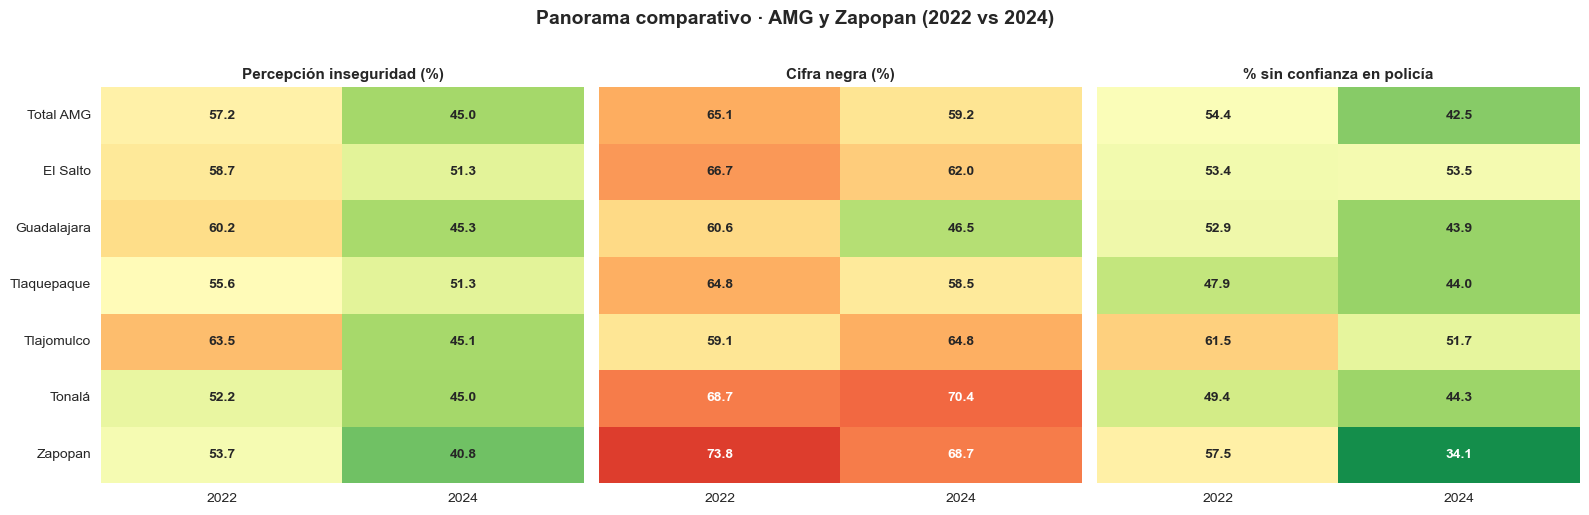

In [ ]:
def pct_nada_confianza(df, codigo):
    """% que respondió 'Nada' de confianza en la policía."""
    sub = df[df["codigo"] == codigo].copy()
    resp = sub["respuesta"].astype(str).str.lower()
    es_nada = resp.str.startswith("nada")
    result = {"Total AMG": sub.loc[es_nada, "total"].sum()}
    for m in MUNICIPIOS:
        if m in sub.columns:
            result[m] = sub.loc[es_nada, m].sum()
    return result


conf_22 = pct_nada_confianza(tidy_2022_limpio, MAPA["confianza_policia"]["2022"])
conf_24 = pct_nada_confianza(tidy_2024_limpio, MAPA["confianza_policia"]["2024"])

orden = ["Total AMG"] + MUNICIPIOS
cifra_ix = tabla_cifra.set_index("Categoría")
comparativo = pd.DataFrame(index=orden)
comparativo["Percepción 2022"]  = [tabla_perc.loc[m, 2022] for m in orden]
comparativo["Percepción 2024"]  = [tabla_perc.loc[m, 2024] for m in orden]
comparativo["Cifra Negra 2022"] = [cifra_ix.loc[m, "Cifra negra 2022 (%)"] for m in orden]
comparativo["Cifra Negra 2024"] = [cifra_ix.loc[m, "Cifra negra 2024 (%)"] for m in orden]
comparativo["Conf. Nada 2022"]  = [conf_22.get(m, np.nan) for m in orden]
comparativo["Conf. Nada 2024"]  = [conf_24.get(m, np.nan) for m in orden]

print("TABLA COMPARATIVA — 3 MÉTRICAS CLAVE POR MUNICIPIO")
display(comparativo.round(1))

#Heatmap
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
paneles = [
    ("Percepción",     "Percepción 2022",  "Percepción 2024",  "Percepción inseguridad (%)"),
    ("Cifra Negra",    "Cifra Negra 2022", "Cifra Negra 2024", "Cifra negra (%)"),
    ("Confianza Nada", "Conf. Nada 2022",  "Conf. Nada 2024",  "% sin confianza en policía"),
]
for ax, (_, c22, c24, titulo) in zip(axes, paneles):
    sub = comparativo[[c22, c24]].copy()
    sub.columns = ["2022", "2024"]
    sns.heatmap(sub, annot=True, fmt=".1f", cmap="RdYlGn_r",
                vmin=30, vmax=80, cbar=False, ax=ax,
                annot_kws={"fontsize": 10, "fontweight": "bold"})
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("")
plt.suptitle("Panorama comparativo · AMG y Zapopan (2022 vs 2024)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## Percepción de inseguridad por SEXO y por EDAD

Estas son las brechas que la ENSU documenta mes con mes, nos permite ver si el patrón del AMG (mujeres > hombres; jóvenes > mayores) se replica en los datos de JCV.

PERCEPCIÓN DE INSEGURIDAD POR SEXO


,2022,2024,Δ (pp)
Hombre,50.6,39.9,-10.7
Mujer,63.3,49.8,-13.5



Brecha Mujer − Hombre:
  2022: +12.7 pp
  2024: +9.9 pp

PERCEPCIÓN DE INSEGURIDAD POR GRUPO DE EDAD


,2022,2024,Δ (pp)
18-29,50.1,38.9,-11.2
30-44,55.9,44.1,-11.8
45-59,62.7,51.3,-11.4
60+,62.4,48.5,-13.9


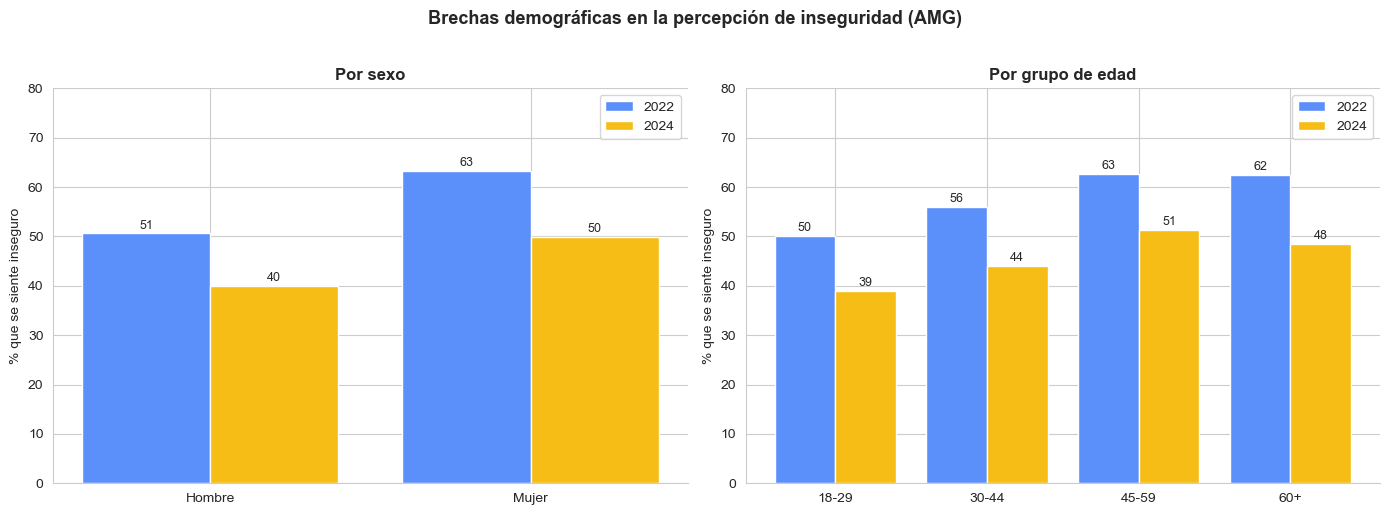

In [28]:
def pct_inseguridad_por_grupo(df, codigo, grupos):
    """% que se siente insegur@ ('Nada seguro' + 'Poco seguro') por grupo."""
    sub = df[df["codigo"] == codigo].copy()
    resp = sub["respuesta"].astype(str).str.lower()
    es_inseguro = resp.str.contains("nada seguro|poco seguro", regex=True)
    return {g: sub.loc[es_inseguro, g].sum() for g in grupos if g in sub.columns}


#Sexo
grupos_sexo = ["Hombre", "Mujer"]
sexo_22 = pct_inseguridad_por_grupo(tidy_2022_limpio, MAPA["percepcion_ciudad"]["2022"], grupos_sexo)
sexo_24 = pct_inseguridad_por_grupo(tidy_2024_limpio, MAPA["percepcion_ciudad"]["2024"], grupos_sexo)

tabla_sexo = pd.DataFrame(
    {
        2022: [sexo_22.get(g, np.nan) for g in grupos_sexo],
        2024: [sexo_24.get(g, np.nan) for g in grupos_sexo],
    },
    index=grupos_sexo,
).round(1)
tabla_sexo["Δ (pp)"] = (tabla_sexo[2024] - tabla_sexo[2022]).round(1)

print("PERCEPCIÓN DE INSEGURIDAD POR SEXO")
display(tabla_sexo)
print(f"\nBrecha Mujer − Hombre:")
print(f"  2022: {tabla_sexo.loc['Mujer', 2022] - tabla_sexo.loc['Hombre', 2022]:+.1f} pp")
print(f"  2024: {tabla_sexo.loc['Mujer', 2024] - tabla_sexo.loc['Hombre', 2024]:+.1f} pp")


#Edad
grupos_edad = ["18-29", "30-44", "45-59", "60+"]
edad_22 = pct_inseguridad_por_grupo(tidy_2022_limpio, MAPA["percepcion_ciudad"]["2022"], grupos_edad)
edad_24 = pct_inseguridad_por_grupo(tidy_2024_limpio, MAPA["percepcion_ciudad"]["2024"], grupos_edad)

tabla_edad = pd.DataFrame(
    {
        2022: [edad_22.get(g, np.nan) for g in grupos_edad],
        2024: [edad_24.get(g, np.nan) for g in grupos_edad],
    },
    index=grupos_edad,
).round(1)
tabla_edad["Δ (pp)"] = (tabla_edad[2024] - tabla_edad[2022]).round(1)

print("\nPERCEPCIÓN DE INSEGURIDAD POR GRUPO DE EDAD")
display(tabla_edad)


#Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (titulo, tabla, etiquetas) in zip(axes, [
    ("Por sexo",           tabla_sexo, grupos_sexo),
    ("Por grupo de edad",  tabla_edad, grupos_edad),
]):
    x = np.arange(len(etiquetas))
    ax.bar(x - 0.2, tabla[2022], 0.4, label="2022", color="#5B8FF9")
    ax.bar(x + 0.2, tabla[2024], 0.4, label="2024", color="#F6BD16")
    ax.set_xticks(x); ax.set_xticklabels(etiquetas)
    ax.set_ylabel("% que se siente inseguro")
    ax.set_title(titulo); ax.set_ylim(0, 80); ax.legend()
    for i, (v22, v24) in enumerate(zip(tabla[2022], tabla[2024])):
        if pd.notna(v22): ax.text(i - 0.2, v22 + 1, f"{v22:.0f}", ha="center", fontsize=9)
        if pd.notna(v24): ax.text(i + 0.2, v24 + 1, f"{v24:.0f}", ha="center", fontsize=9)
    sns.despine(ax=ax)

plt.suptitle("Brechas demográficas en la percepción de inseguridad (AMG)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

## Razones para NO denunciar (2022 vs 2024)

Solo se pregunta a quienes NO denunciaron, en la tabla de datos crudos, "No aplica" ocupa ~90% (son no-víctimas o sí-denunciantes).
Filtramos esas filas y RENORMALIZAMOS a 100% para ver la distribución relativa de razones entre quienes no denunciaron.

NOTA DE HOMOLOGACIÓN:
En 2022, "No sirve para nada" y "Pérdida de tiempo" son categorías SEPARADAS, pero en 2024 vienen COMBINADAS como "No sirve para nada / Pérdida de tiempo", para comparar, conviene leer 2022 como su suma o notar la discrepancia.

RAZONES PARA NO DENUNCIAR — 2022 (% de quienes no denunciaron)


,respuesta,total,pct
0,No sirve para nada,2.2,23.2
1,Pérdida de tiempo,2.1,22.1
2,No tenía pruebas,1.3,13.7
3,Delito de poca importancia,1.0,10.5
4,Desconfianza en la autoridad,1.0,10.5
5,"Otra razón, ¿cuál?",0.6,6.3
6,Por miedo al agreso(es),0.4,4.2
7,Por actitud negativa de la autoridad,0.4,4.2
8,No sabía en donde denunciar,0.3,3.2
9,Por miedo a que la/lo extorsionen,0.1,1.1



RAZONES PARA NO DENUNCIAR — 2024 (% de quienes no denunciaron)


,respuesta,total,pct
0,No sirve para nada / Pérdida de tiempo,3.3,40.2
1,Desconfianza en la autoridad,1.4,17.1
2,Delito de poca importancia,1.3,15.9
3,No tenía pruebas,0.6,7.3
4,Otra razón,0.6,7.3
5,No sabía en donde denunciar,0.3,3.7
6,Por miedo al agresor(es) o que la/lo extorsionen,0.3,3.7
7,Por actitud negativa de la autoridad,0.2,2.4
8,Trámites largos y difíciles,0.2,2.4
9,Ubicación de la Fiscalía,NaN,NaN


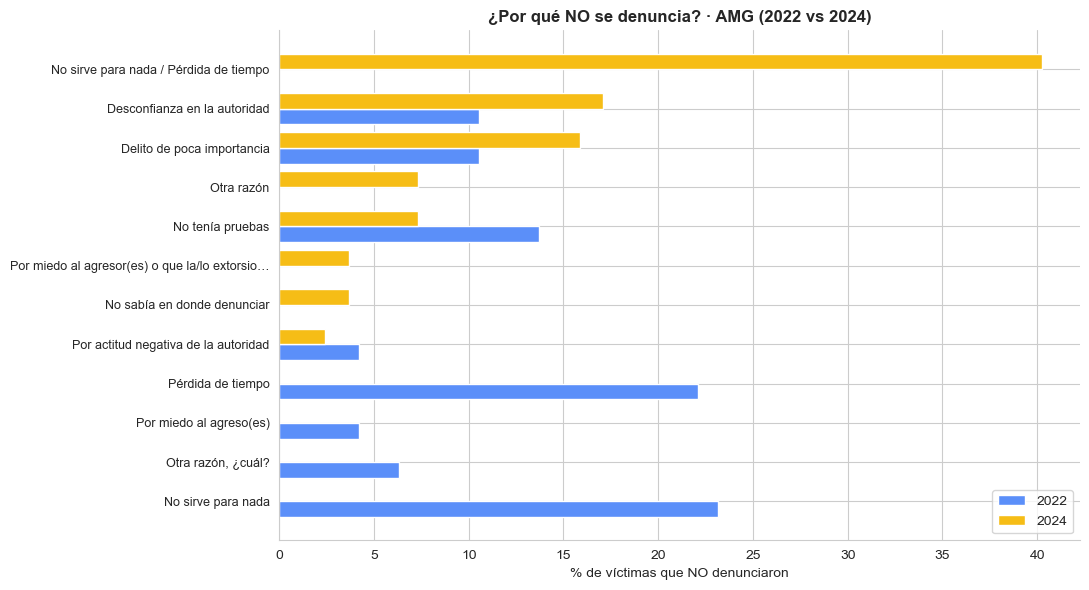


INSIGHT: Top 3 razones para no denunciar
  2022:
    1. No sirve para nada: 23.2%
    2. Pérdida de tiempo: 22.1%
    3. No tenía pruebas: 13.7%
  2024:
    1. No sirve para nada / Pérdida de tiempo: 40.2%
    2. Desconfianza en la autoridad: 17.1%
    3. Delito de poca importancia: 15.9%


In [29]:
def razones_no_denuncia(df, codigo):
    sub = df[df["codigo"] == codigo].copy()
    resp = sub["respuesta"].astype(str).str.strip().str.lower()
    excluir = resp.str.contains("no aplica|no sabe|no contestó|no sabría")
    sub = sub[~excluir].copy()
    if sub.empty:
        return pd.DataFrame()
    total = sub["total"].sum()
    sub["pct"] = sub["total"] / total * 100
    return sub[["respuesta", "total", "pct"]].sort_values("pct", ascending=False)


razones_22 = razones_no_denuncia(tidy_2022_limpio, MAPA["razon_no_denuncio"]["2022"])
razones_24 = razones_no_denuncia(tidy_2024_limpio, MAPA["razon_no_denuncio"]["2024"])

print("RAZONES PARA NO DENUNCIAR — 2022 (% de quienes no denunciaron)")
display(razones_22.round(1).head(10).reset_index(drop=True))
print("\nRAZONES PARA NO DENUNCIAR — 2024 (% de quienes no denunciaron)")
display(razones_24.round(1).head(10).reset_index(drop=True))


#Top razones comparadas
top22 = razones_22.head(8).set_index("respuesta")["pct"]
top24 = razones_24.head(8).set_index("respuesta")["pct"]
todas = sorted(set(top22.index) | set(top24.index))
datos = pd.DataFrame({
    "2022": [top22.get(r, 0) for r in todas],
    "2024": [top24.get(r, 0) for r in todas],
}, index=todas).sort_values("2024")

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(datos))
ax.barh(y - 0.2, datos["2022"], 0.4, label="2022", color="#5B8FF9")
ax.barh(y + 0.2, datos["2024"], 0.4, label="2024", color="#F6BD16")
ax.set_yticks(y)
ax.set_yticklabels([r[:45] + "…" if len(r) > 45 else r for r in datos.index], fontsize=9)
ax.set_xlabel("% de víctimas que NO denunciaron")
ax.set_title("¿Por qué NO se denuncia? · AMG (2022 vs 2024)")
ax.legend(); sns.despine(ax=ax); plt.tight_layout(); plt.show()

print("\nINSIGHT: Top 3 razones para no denunciar")
for anio, top in [("2022", top22), ("2024", top24)]:
    print(f"  {anio}:")
    for i, (razon, pct) in enumerate(top.head(3).items(), 1):
        print(f"    {i}. {razon}: {pct:.1f}%")

## Comparación JCV vs ENSU (referencia externa)

Objetivo: comparar la tendencia del AMG con el instrumento oficial.

ADVERTENCIA: distintos instrumentos, distinto muestreo, distinto periodo, la comparación NO es de nivel absoluto, sino de DIRECCIÓN y ORDEN.

JCV (Oct 2024) vs ENSU (Mar 2026) — percepción de inseguridad en la ciudad


,JCV Oct 2024 (%),ENSU Mar 2026 (%),Δ (pp)
Municipio,,,
El Salto,51.3,NaN,NaN
Guadalajara,45.3,90.2,44.9
Tlaquepaque,51.3,62.5,11.2
Tlajomulco,45.1,70.1,25.0
Tonalá,45.0,68.1,23.1
Zapopan,40.8,70.8,30.0



NOTA ANALÍTICA:
1. Los niveles absolutos son MUY distintos entre instrumentos:
   · JCV Oct 2024  → 40-51% (AMG)
   · ENSU Mar 2026 → 62-90% (AMG)

2. Posibles explicaciones:
   1. Diferencia temporal (~17 meses entre levantamientos).
   2. Marco muestral: JCV pondera por municipio completo;
      ENSU levanta SOLO en zonas urbanas de cada municipio.
   3. Posible cambio real de percepción entre 2024 y 2026.

3. Uso recomendado para el artículo:
   · JCV → tendencias, desagregados, cruces (lo que ya hiciste).
   · ENSU → niveles absolutos comparables con el resto del país.
   · NO mezclar los dos como si fueran la misma serie.



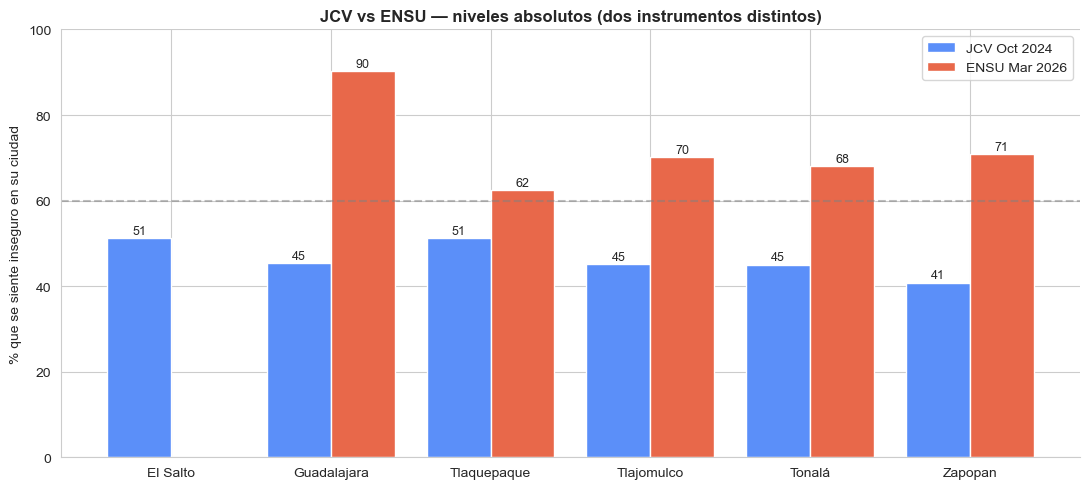

In [31]:
ensu_ref = pd.DataFrame({
    "Municipio": MUNICIPIOS,
    "JCV Oct 2024 (%)":  [tabla_perc.loc[m, 2024] for m in MUNICIPIOS],
    "ENSU Mar 2026 (%)": [
        np.nan,   # El Salto no está en ENSU
        90.2,     # Guadalajara
        62.5,     # Tlaquepaque
        70.1,     # Tlajomulco
        68.1,     # Tonalá
        70.8,     # Zapopan
    ],
}).set_index("Municipio")

ensu_ref["Δ (pp)"] = (ensu_ref["ENSU Mar 2026 (%)"] - ensu_ref["JCV Oct 2024 (%)"]).round(1)

print("JCV (Oct 2024) vs ENSU (Mar 2026) — percepción de inseguridad en la ciudad")
display(ensu_ref.round(1))

print("""
NOTA ANALÍTICA:
1. Los niveles absolutos son MUY distintos entre instrumentos:
   · JCV Oct 2024  → 40-51% (AMG)
   · ENSU Mar 2026 → 62-90% (AMG)

2. Posibles explicaciones:
   1. Diferencia temporal (~17 meses entre levantamientos).
   2. Marco muestral: JCV pondera por municipio completo;
      ENSU levanta SOLO en zonas urbanas de cada municipio.
   3. Posible cambio real de percepción entre 2024 y 2026.

3. Uso recomendado para el artículo:
   · JCV → tendencias, desagregados, cruces (lo que ya hiciste).
   · ENSU → niveles absolutos comparables con el resto del país.
   · NO mezclar los dos como si fueran la misma serie.
""")

#Visualización comparativa
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(ensu_ref))
ax.bar(x - 0.2, ensu_ref["JCV Oct 2024 (%)"], 0.4,
       label="JCV Oct 2024", color="#5B8FF9")
ax.bar(x + 0.2, ensu_ref["ENSU Mar 2026 (%)"], 0.4,
       label="ENSU Mar 2026", color="#E8684A")
ax.set_xticks(x); ax.set_xticklabels(ensu_ref.index)
ax.set_ylabel("% que se siente inseguro en su ciudad")
ax.set_title("JCV vs ENSU — niveles absolutos (dos instrumentos distintos)")
ax.set_ylim(0, 100); ax.legend()
ax.axhline(60, color="gray", linestyle="--", alpha=0.5)
for i, (v22, v24) in enumerate(zip(ensu_ref["JCV Oct 2024 (%)"], ensu_ref["ENSU Mar 2026 (%)"])):
    if pd.notna(v22): ax.text(i - 0.2, v22 + 1, f"{v22:.0f}", ha="center", fontsize=9)
    if pd.notna(v24): ax.text(i + 0.2, v24 + 1, f"{v24:.0f}", ha="center", fontsize=9)
sns.despine(ax=ax); plt.tight_layout(); plt.show()

## Exportación de tablas procesadas + resumen ejecutivo

Guarda los DataFrames clave en ../datos/procesada/ para que los puedo consumir el artículo en LaTeX sin re-ejecutar el notebook.\
Imprime un resumen con los hallazgos principales.

In [36]:
DIR_PROCESADA = Path("../datos/procesados")
DIR_PROCESADA.mkdir(parents=True, exist_ok=True)

#Tidy completos
tidy_2022_limpio.to_csv(DIR_PROCESADA / "tidy_2022_limpio.csv", index=False, encoding="utf-8")
tidy_2024_limpio.to_csv(DIR_PROCESADA / "tidy_2024_limpio.csv", index=False, encoding="utf-8")

#Tablas resumen
tabla_perc.to_csv(DIR_PROCESADA / "tabla_percepcion.csv", encoding="utf-8")
tabla_cifra.to_csv(DIR_PROCESADA / "tabla_cifra_negra.csv", index=False, encoding="utf-8")
comparativo.to_csv(DIR_PROCESADA / "tabla_comparativo_3metricas.csv", encoding="utf-8")
tabla_sexo.to_csv(DIR_PROCESADA / "tabla_por_sexo.csv", encoding="utf-8")
tabla_edad.to_csv(DIR_PROCESADA / "tabla_por_edad.csv", encoding="utf-8")
ensu_ref.to_csv(DIR_PROCESADA / "tabla_jcv_vs_ensu.csv", encoding="utf-8")

print("Exportados a:", DIR_PROCESADA.resolve())
for f in sorted(DIR_PROCESADA.glob("*.csv")):
    print(f"   · {f.name}")

#Resumen ejecutivo 
amg_22 = tabla_perc.loc["Total AMG", 2022]
amg_24 = tabla_perc.loc["Total AMG", 2024]
zap_22 = tabla_perc.loc["Zapopan", 2022]
zap_24 = tabla_perc.loc["Zapopan", 2024]
cn = tabla_cifra.set_index("Categoría")

print("\n")
print("RESUMEN EJECUTIVO:")
print(f"""
1. PERCEPCIÓN DE INSEGURIDAD EN LA CIUDAD
   - AMG:     {amg_22:.1f}% (2022) → {amg_24:.1f}% (2024)   Δ {amg_24-amg_22:+.1f} pp
   - Zapopan: {zap_22:.1f}% (2022) → {zap_24:.1f}% (2024)   Δ {zap_24-zap_22:+.1f} pp
   → Desciende en todos los municipios del AMG. Zapopan queda como el municipio con MENOR percepción de inseguridad en 2024.

2. CIFRA NEGRA (% de víctimas que NO denuncian)
   - AMG:     {cn.loc['Total AMG', 'Cifra negra 2022 (%)']:.1f}% → {cn.loc['Total AMG', 'Cifra negra 2024 (%)']:.1f}%
   - Zapopan: {cn.loc['Zapopan',   'Cifra negra 2022 (%)']:.1f}% → {cn.loc['Zapopan',   'Cifra negra 2024 (%)']:.1f}%
   → Zapopan mantiene una cifra negra muy alta: >2/3 de las víctimas NO denuncian, es uno de los municipios con mayor subregistro.

3. CONFIANZA EN LA POLICÍA (% "Nada")
   - AMG:     {conf_22['Total AMG']:.1f}% → {conf_24['Total AMG']:.1f}%
   - Zapopan: {conf_22['Zapopan']:.1f}% → {conf_24['Zapopan']:.1f}%
   → Mejora, pero sigue muy alta la desconfianza total.

4. LECTURA PARA LA TESIS
   Aunque la percepción y la confianza mejoraron 2022→2024, la cifra negra sigue muy elevada y la desconfianza total en la policía afecta
   a 1 de cada 3 habitantes de Zapopan, esto apoya una lectura de CRISIS DE CONFIANZA INSTITUCIONAL ESTRUCTURAL: los cambios en la percepción no se 
   traducen automáticamente en mayor disposición a denunciar ni en mayor confianza en las corporaciones.
""")

Exportados a: C:\Users\josue\Downloads\La_percepcion_de_inseguridad_en_ZMG\datos\procesados
   · tabla_cifra_negra.csv
   · tabla_comparativo_3metricas.csv
   · tabla_jcv_vs_ensu.csv
   · tabla_percepcion.csv
   · tabla_por_edad.csv
   · tabla_por_sexo.csv
   · tidy_2022_limpio.csv
   · tidy_2024_limpio.csv


RESUMEN EJECUTIVO:

1. PERCEPCIÓN DE INSEGURIDAD EN LA CIUDAD
   - AMG:     57.2% (2022) → 45.0% (2024)   Δ -12.2 pp
   - Zapopan: 53.7% (2022) → 40.8% (2024)   Δ -12.9 pp
   → Desciende en todos los municipios del AMG. Zapopan queda como el municipio con MENOR percepción de inseguridad en 2024.

2. CIFRA NEGRA (% de víctimas que NO denuncian)
   - AMG:     65.1% → 59.2%
   - Zapopan: 73.8% → 68.7%
   → Zapopan mantiene una cifra negra muy alta: >2/3 de las víctimas NO denuncian, es uno de los municipios con mayor subregistro.

3. CONFIANZA EN LA POLICÍA (% "Nada")
   - AMG:     54.4% → 42.5%
   - Zapopan: 57.5% → 34.1%
   → Mejora, pero sigue muy alta la desconfianza total.

4. L

## Regenerar TODAS las figuras y exportarlas a docs/figuras/

Este bloque vuelve a graficar cada hallazgo y guarda cada figura en PNG (300 dpi) y PDF (vectorial, para LaTeX). Nombres alineados al orden en que aparecen en el paper.

In [37]:
DIR_FIGURAS = Path("../docs/figuras")
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)


def guardar_figura(fig, nombre: str, dpi: int = 300):
    """Guarda una figura en PNG (300 dpi) y PDF (vectorial)."""
    for fmt in ("png", "pdf"):
        ruta = DIR_FIGURAS / f"{nombre}.{fmt}"
        fig.savefig(ruta, dpi=dpi, bbox_inches="tight", facecolor="white")
    print(f"{nombre}.png / .pdf")


#FIG 1 — Percepción de inseguridad por municipio (2022 vs 2024)
fig, ax = plt.subplots(figsize=(11, 5.5))
plot = tabla_perc.drop(index="Total AMG", errors="ignore")
x = np.arange(len(plot)); ancho = 0.38
b22 = ax.bar(x - ancho/2, plot[2022], ancho, label="2022", color="#5B8FF9", edgecolor="white")
b24 = ax.bar(x + ancho/2, plot[2024], ancho, label="2024", color="#F6BD16", edgecolor="white")
for b in list(b22) + list(b24):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1,
            f"{b.get_height():.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(plot.index)
ax.set_ylabel("% que se siente inseguro en su ciudad")
ax.set_title("Percepción de inseguridad en la ciudad · AMG (2022 vs 2024)")
ax.set_ylim(0, 80)
ax.axhline(50, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
ax.legend(title="Año"); sns.despine(); plt.tight_layout()
guardar_figura(fig, "fig01_percepcion_por_municipio"); plt.close(fig)


#FIG 2 — Confianza en la policía (Zapopan vs AMG)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (anio, d, color) in zip(
    axes, [(2022, d22, "#5B8FF9"), (2024, d24, "#F6BD16")]):
    idx = np.arange(len(d)); ancho = 0.38
    ax.bar(idx - ancho/2, d["Total AMG"], ancho, label="Total AMG", color=color, alpha=0.55, edgecolor="white")
    ax.bar(idx + ancho/2, d["Zapopan"], ancho, label="Zapopan", color=color, edgecolor="black")
    ax.set_xticks(idx); ax.set_xticklabels(d.index, rotation=20, ha="right")
    ax.set_title(f"Confianza en la policía · {anio}")
    ax.set_ylabel("% de respuestas"); ax.set_ylim(0, 70); ax.legend(fontsize=9)
    sns.despine(ax=ax)
plt.suptitle("Confianza en la policía — Zapopan vs Total AMG (2022 vs 2024)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
guardar_figura(fig, "fig02_confianza_policia"); plt.close(fig)


#FIG 3 — Heatmap de 3 métricas clave
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
paneles = [
    ("Percepción 2022", "Percepción 2024", "Percepción inseguridad (%)"),
    ("Cifra Negra 2022", "Cifra Negra 2024", "Cifra negra (%)"),
    ("Conf. Nada 2022", "Conf. Nada 2024", "% sin confianza en policía"),
]
for ax, (c22, c24, titulo) in zip(axes, paneles):
    sub = comparativo[[c22, c24]].copy(); sub.columns = ["2022", "2024"]
    sns.heatmap(sub, annot=True, fmt=".1f", cmap="RdYlGn_r",
                vmin=30, vmax=80, cbar=False, ax=ax,
                annot_kws={"fontsize": 10, "fontweight": "bold"})
    ax.set_title(titulo, fontsize=11); ax.set_xlabel("")
plt.suptitle("Panorama comparativo · AMG y Zapopan (2022 vs 2024)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
guardar_figura(fig, "fig03_heatmap_3metricas"); plt.close(fig)


#FIG 4 — Brechas sexo + edad
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (titulo, tabla, etiquetas) in zip(axes, [
    ("Por sexo", tabla_sexo, grupos_sexo),
    ("Por grupo de edad", tabla_edad, grupos_edad),
]):
    x = np.arange(len(etiquetas))
    ax.bar(x - 0.2, tabla[2022], 0.4, label="2022", color="#5B8FF9")
    ax.bar(x + 0.2, tabla[2024], 0.4, label="2024", color="#F6BD16")
    ax.set_xticks(x); ax.set_xticklabels(etiquetas)
    ax.set_ylabel("% que se siente inseguro"); ax.set_ylim(0, 80)
    ax.set_title(titulo); ax.legend()
    for i, (v22, v24) in enumerate(zip(tabla[2022], tabla[2024])):
        if pd.notna(v22): ax.text(i - 0.2, v22 + 1, f"{v22:.0f}", ha="center", fontsize=9)
        if pd.notna(v24): ax.text(i + 0.2, v24 + 1, f"{v24:.0f}", ha="center", fontsize=9)
    sns.despine(ax=ax)
plt.suptitle("Brechas demográficas en la percepción de inseguridad (AMG)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
guardar_figura(fig, "fig04_brechas_sexo_edad"); plt.close(fig)


#FIG 5 — Razones para NO denunciar
top22 = razones_22.head(8).set_index("respuesta")["pct"]
top24 = razones_24.head(8).set_index("respuesta")["pct"]
todas = sorted(set(top22.index) | set(top24.index))
datos = pd.DataFrame({"2022": [top22.get(r, 0) for r in todas],
                      "2024": [top24.get(r, 0) for r in todas]}, index=todas).sort_values("2024")

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(datos))
ax.barh(y - 0.2, datos["2022"], 0.4, label="2022", color="#5B8FF9")
ax.barh(y + 0.2, datos["2024"], 0.4, label="2024", color="#F6BD16")
ax.set_yticks(y)
ax.set_yticklabels([r[:45] + "…" if len(r) > 45 else r for r in datos.index], fontsize=9)
ax.set_xlabel("% de víctimas que NO denunciaron")
ax.set_title("¿Por qué NO se denuncia? · AMG (2022 vs 2024)")
ax.legend(); sns.despine(ax=ax); plt.tight_layout()
guardar_figura(fig, "fig05_razones_no_denuncia"); plt.close(fig)


#FIG 6 — JCV vs ENSU
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(ensu_ref))
ax.bar(x - 0.2, ensu_ref["JCV Oct 2024 (%)"], 0.4, label="JCV Oct 2024", color="#5B8FF9")
ax.bar(x + 0.2, ensu_ref["ENSU Mar 2026 (%)"], 0.4, label="ENSU Mar 2026", color="#E8684A")
ax.set_xticks(x); ax.set_xticklabels(ensu_ref.index)
ax.set_ylabel("% que se siente inseguro en su ciudad")
ax.set_title("JCV vs ENSU — niveles absolutos (instrumentos distintos)")
ax.set_ylim(0, 100); ax.legend(); ax.axhline(60, color="gray", linestyle="--", alpha=0.5)
for i, (v22, v24) in enumerate(zip(ensu_ref["JCV Oct 2024 (%)"], ensu_ref["ENSU Mar 2026 (%)"])):
    if pd.notna(v22): ax.text(i - 0.2, v22 + 1, f"{v22:.0f}", ha="center", fontsize=9)
    if pd.notna(v24): ax.text(i + 0.2, v24 + 1, f"{v24:.0f}", ha="center", fontsize=9)
sns.despine(ax=ax); plt.tight_layout()
guardar_figura(fig, "fig06_jcv_vs_ensu"); plt.close(fig)


print("\nFiguras en:", DIR_FIGURAS.resolve())

fig01_percepcion_por_municipio.png / .pdf
fig02_confianza_policia.png / .pdf
fig03_heatmap_3metricas.png / .pdf
fig04_brechas_sexo_edad.png / .pdf
fig05_razones_no_denuncia.png / .pdf
fig06_jcv_vs_ensu.png / .pdf

Figuras en: C:\Users\josue\Downloads\La_percepcion_de_inseguridad_en_ZMG\docs\figuras
